<a href="https://colab.research.google.com/github/lhy2030/CAP-VTON/blob/main/Start_CaP_VTON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
if not os.path.exists("/content/CAP-VTON"):
    !git clone https://github.com/lhy2030/CAP-VTON.git
%cd /content/CAP-VTON

/content/CAP-VTON


In [2]:
!pip install -r requirements.txt
!pip install "transformers>=4.50,<5"
!pip install "diffusers==0.35.2"

INFO: pip is looking at multiple versions of transformers to determine which version is compatible with other requirements. This could take a while.
  Using cached transformers-5.22.2-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.22.0-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.21.1-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.21.0-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.20.2-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.20.1-py3-none-any.whl.metadata (31 kB)
INFO: pip is still looking at multiple versions of transformers to determine which version is compatible with other requirements. This could take a while.
  Using cached transformers-5.20.0-py3-none-any.whl.metadata (31 kB)
  Using cached transformers-5.19.0-py3-none-any.whl.metadata (32 kB)
  Using cached transformers-5.18.0-py3-none-any.whl.metadata (32 kB)
  Using cached transformers-5.17.0-py3-none-any.whl.metadata (32 kB)
  Usin

In [3]:
from huggingface_hub import snapshot_download

# Download checkpoints
snapshot_download(repo_id="franciszzj/Leffa", local_dir="./ckpts")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 37 files:   0%|          | 0/37 [00:00<?, ?it/s]

'/content/CAP-VTON/ckpts'

In [4]:
!mkdir -p ./ckpts
!wget -O ./ckpts/majicmixRealistic_v7.safetensors https://huggingface.co/GreenGrape/231209/resolve/main/majicmixRealistic_v7.safetensors

--2026-11-10 14:46:16--  https://huggingface.co/GreenGrape/231209/resolve/main/majicmixRealistic_v7.safetensors
Resolving huggingface.co (huggingface.co)... 13.35.202.34, 13.35.202.121, 13.35.202.40, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.34|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/657473e939831c68627d920b/1ea5890691eea2f1e8b8ef44580dd88bc3ab17bc20cdf535370cccf3f03a0914?xip=eXYyZ6sc3Ck&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27majicmixRealistic_v7.safetensors%3B+filename%3D%22majicmixRealistic_v7.safetensors%22%3B&X-Xet-Cas-Uid=public&user_id=public&Expires=1794325576&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjU3NDczZTkzOTgzMWM2ODYyN2Q5MjBiLzFlYTU4OTA2OTFlZWEyZjFlOGI4ZWY0NDU4MGRkODhiYzNhYjE3YmMyMGNkZjUzNTM3MGNjY2YzZjAzYTA5MTRcXD94aXA9ZVhZeVo2c2MzQ2smcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj0qJlgtWGV0LUNhcy1VaWQ9cHVibGlj

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1110 14:48:17.613000 13402 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.
100%|██████████| 1/1 [00:00<00:00,  1.85it/s]


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet_inpaint.StableDiffusionControlNetInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.f

  0%|          | 0/25 [00:00<?, ?it/s]

Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

Ground Truth saved at: output/ground_truth.png
Prediction saved at: output/prediction.png


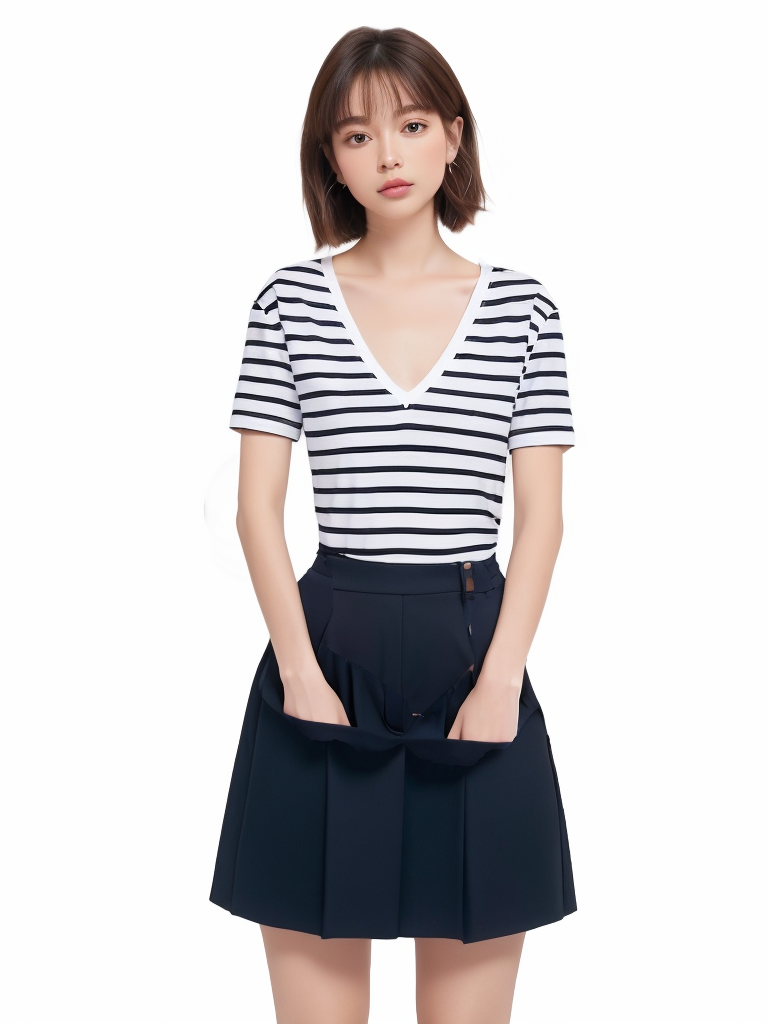

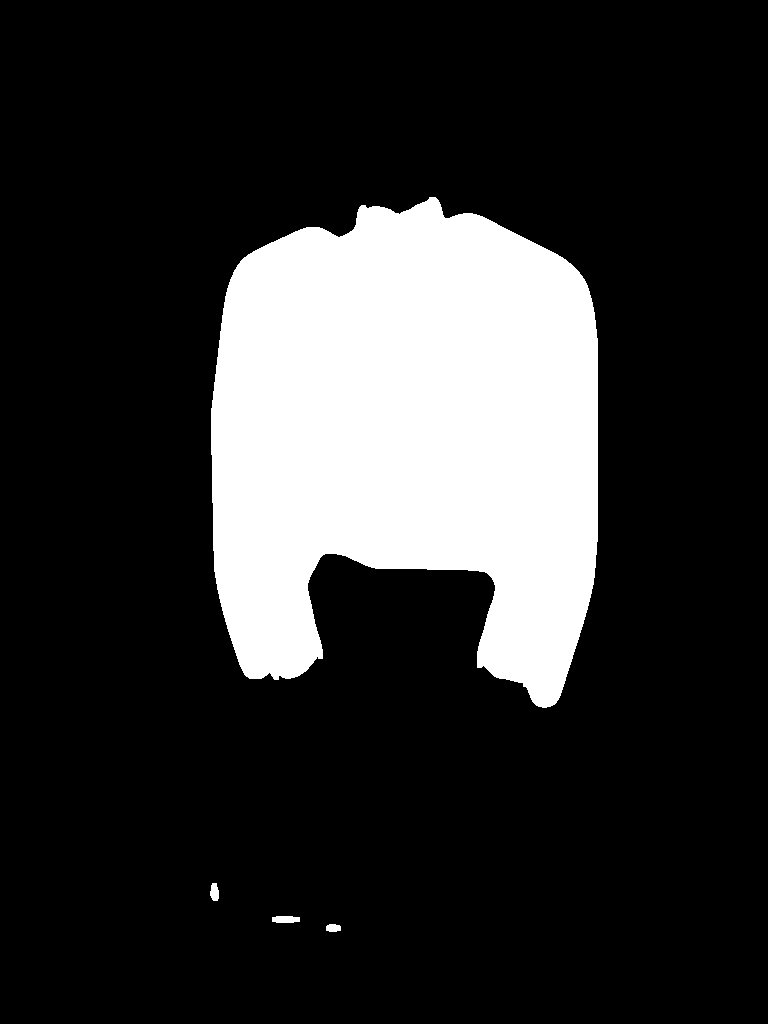

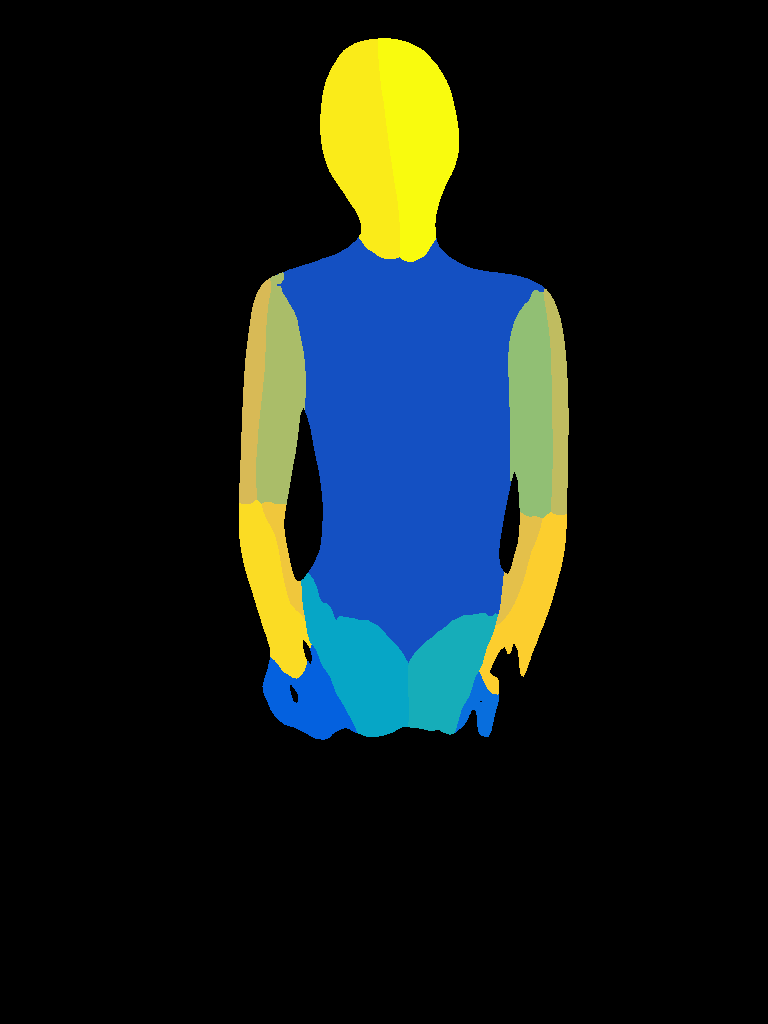

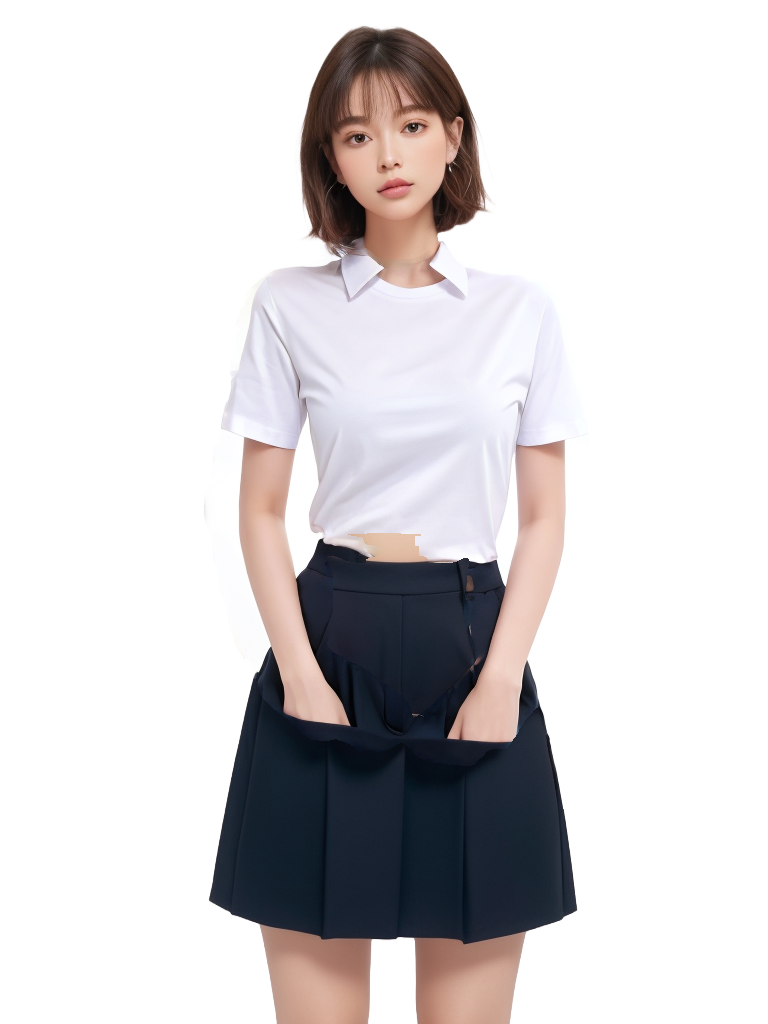

In [5]:
from vton_script import CAPVirtualTryOn
from IPython.display import display
import os

vton = CAPVirtualTryOn(ckpt_dir="./ckpts")

output_dir = "output"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

gen_image, mask, densepose, agnostic_image = vton.capvton_predict( #test : s0340.png  ,  s0328.png   ,   s0303.png
    src_image_path="in_img/입력이미지1.png",
    ref_image_path="in_img/s0303.png",
    control_type="virtual_tryon",
    vt_model_type="viton_hd",  # "viton_hd", "dress_code"
    vt_garment_type="upper_body",  # upper_body, dresses, lower_body, short_sleeve, shorts
    step=25,
    cross_attention_kwargs=3,
    vt_repaint=False,
    output_path=f"{output_dir}/virtual_tryon_result2.jpg"
)

display(gen_image)

display(mask)

display(densepose)

display(agnostic_image)